In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 10,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

vib_blue = "#0C7BDC"
teal = "#40B0A6"
purple = "#5D3A9B" 

In [12]:
base_path = "/Users/honeyeah/Codes/data/" #folder with all data

sim_set = "merger_rebound/" #name of simulation set, folder with subfolders the name "sim_set_i"
sim_archive_path = base_path + sim_set + "merger_" #path given to get_runtime_data function
merger_reb_rdf = rr.get_runtime_data(sim_archive_path, 10, "merger_") #rdf is runtime data frame

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.10. You are currently using REBOUND Version 4.4.8.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: Ru

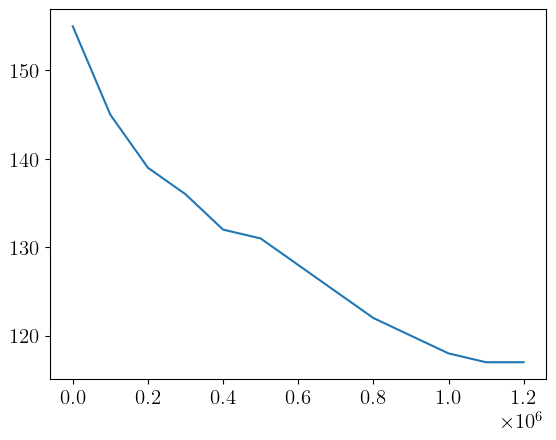

In [13]:
for i in range(1):
    sim = merger_reb_rdf[merger_reb_rdf['simulation_id'] == i+1]
    plt.plot(sim['time'], sim['N_bodies'])

plt.show()

In [14]:
sim1 = merger_reb_rdf[merger_reb_rdf['simulation_id']==1]

# GENGA output reading

In [15]:
path = '/Users/honeyeah/Codes/data/genga_merger_output_aei/'
colnames = ['time', 'i', 'a', 'e', 'inc',
            'Omega', 'w', 'Theta', 'E', 'M', 'm', 'r']

# Generate the filenames at intervals of 1e7
file_indices = list(range(0, 2310700000, 100000))
filenames = [f"aeimerger_{i:012d}.dat" for i in file_indices]

In [16]:
frames = np.linspace(0,len(file_indices), len(file_indices) + 1)

In [17]:
genga_dfs = []
genga_n_bodies = []
genga_times = []
for i in range(len(file_indices)):
    filepath = os.path.join(path, filenames[i])
    df = pd.read_csv(filepath, sep=r"\s+", names=colnames, header=None)
    genga_dfs.append(df)
    genga_n_bodies.append(len(df))

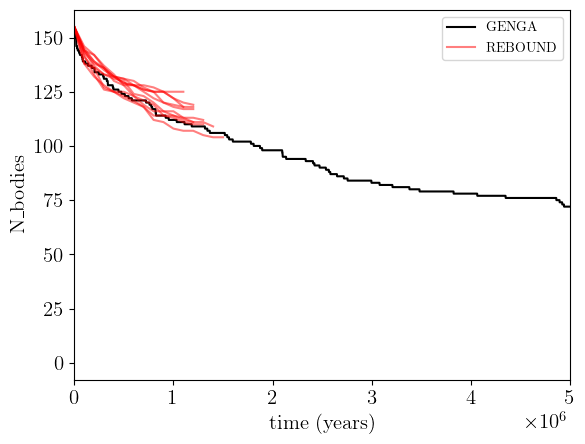

In [26]:
time = np.array(file_indices) * (6/365)
plt.plot(time, genga_n_bodies, label = 'GENGA', color = 'black')
for i in range(10):
    sim = merger_reb_rdf[merger_reb_rdf['simulation_id'] == i+1]
    if i == 2:
        plt.plot(sim['time'], sim['N_bodies'], label = 'REBOUND', color='red', alpha = 0.5)
    else:
        plt.plot(sim['time'], sim['N_bodies'], color = 'red', alpha = 0.5)

plt.xlim(0,5e6)
plt.xlabel('time (years)')
plt.ylabel('N_bodies')
plt.legend()
plt.show()